### Mount Drive, initialise Spark, and load the verified Task 2 outputs.


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.ml.linalg import VectorUDT, Vectors
from pyspark.ml.functions import vector_to_array, array_to_vector
from pyspark.ml.classification import (
    LogisticRegression, RandomForestClassifier,
    GBTClassifier, MultilayerPerceptronClassifier
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

spark = (
    SparkSession.builder
    .appName("7006SCN_Task5_WESAD_Evaluation_Stability")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

TASK2_DIR = Path("/content/drive/MyDrive/wesad_task2_outputs")
TRAIN_PATH = TASK2_DIR / "train_processed"
TEST_PATH = TASK2_DIR / "test_processed"
MANIFEST_PATH = TASK2_DIR / "task2_manifest.json"

if not TRAIN_PATH.exists() or not TEST_PATH.exists() or not MANIFEST_PATH.exists():
    raise FileNotFoundError("Verified Task 2 train/test outputs and manifest are required.")
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
if manifest.get("status") != "verified":
    raise RuntimeError("Task 2 manifest is not marked verified.")

train_full = spark.read.parquet(str(TRAIN_PATH))
test_full = spark.read.parquet(str(TEST_PATH))
required = {"features", "label", "target_text", "subject_id", "sample_index"}
for name, frame in [("train", train_full), ("test", test_full)]:
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"{name} data is missing columns: {missing}")

print("Spark version:", spark.version)
print("Training rows:", f"{train_full.count():,}")
print("Test rows:", f"{test_full.count():,}")
print("Task 2 manifest status:", manifest["status"])

Mounted at /content/drive
Spark version: 4.0.4
Training rows: 25,137,704
Test rows: 6,332,899
Task 2 manifest status: verified


### Create bounded, reproducible evaluation datasets from the participant-separated Task 2 split.


In [ ]:
MAX_TRAIN_ROWS = 200_000
MAX_TEST_ROWS = 100_000
SEED = 42

def bounded_stratified_sample(frame, max_rows, seed):
    total = frame.count()
    if total <= max_rows:
        return frame
    fraction = min(1.0, (max_rows * 1.20) / total)
    labels = [r["label"] for r in frame.select("label").distinct().collect()]
    fractions = {label: fraction for label in labels}
    sampled = frame.stat.sampleBy("label", fractions=fractions, seed=seed)
    if sampled.count() > max_rows:
        sampled = sampled.orderBy(F.rand(seed=seed)).limit(max_rows)
    return sampled

train_sample = bounded_stratified_sample(train_full, MAX_TRAIN_ROWS, SEED).cache()
test = bounded_stratified_sample(test_full, MAX_TEST_ROWS, SEED + 1).cache()
train_n, test_n = train_sample.count(), test.count()

label_mapping = [
    (int(r["label"]), str(r["target_text"]))
    for r in train_sample.select("label", "target_text").distinct().orderBy("label", "target_text").collect()
]
print("Numeric label to target_text mapping:", label_mapping)

mapping = {}
for numeric_label, text_label in label_mapping:
    if numeric_label in mapping and mapping[numeric_label] != text_label:
        raise RuntimeError(f"Numeric label {numeric_label} maps to multiple target_text values.")
    mapping[numeric_label] = text_label

if set(mapping.values()) != {"non_stress", "stress"}:
    raise RuntimeError(f"Unexpected label mapping: {mapping}")
stress_labels = [label for label, text_label in mapping.items() if text_label == "stress"]
if len(stress_labels) != 1:
    raise RuntimeError(f"Could not identify one stress label from mapping: {mapping}")
POSITIVE_LABEL = int(stress_labels[0])
print("Positive class (stress):", POSITIVE_LABEL)

train_subjects = sorted(r["subject_id"] for r in train_sample.select("subject_id").distinct().collect())
test_subjects = sorted(r["subject_id"] for r in test.select("subject_id").distinct().collect())
overlap = sorted(set(train_subjects).intersection(test_subjects))
if overlap:
    raise RuntimeError(f"Participant leakage detected: {overlap}")
if train_sample.select("label").distinct().count() != 2 or test.select("label").distinct().count() != 2:
    raise RuntimeError("Both classes must be present in training and test samples.")

feature_size = train_sample.select(F.size(vector_to_array("features")).alias("n")).first()["n"]
fit_train, threshold_validation = train_sample.randomSplit([0.80, 0.20], seed=SEED)
fit_train = fit_train.cache()
threshold_validation = threshold_validation.cache()
print("Training sample rows:", f"{train_n:,}")
print("Model-fitting rows:", f"{fit_train.count():,}")
print("Threshold-validation rows:", f"{threshold_validation.count():,}")
print("Test sample rows:", f"{test_n:,}")
print("Feature count:", feature_size)
print("Training participants:", train_subjects)
print("Test participants:", test_subjects)
print("Participant overlap:", overlap)
print("Training label distribution:")
train_sample.groupBy("label", "target_text").count().orderBy("label").show()


Numeric label to target_text mapping: [(0, 'non_stress'), (1, 'stress')]
Positive class (stress): 1
Training sample rows: 200,000
Model-fitting rows: 159,826
Threshold-validation rows: 40,174
Test sample rows: 100,000
Feature count: 8
Training participants: ['S10', 'S11', 'S13', 'S14', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
Test participants: ['S15', 'S16', 'S17']
Participant overlap: []
Training label distribution:
+-----+-----------+------+
|label|target_text| count|
+-----+-----------+------+
|  0.0| non_stress|156102|
|  1.0|     stress| 43898|
+-----+-----------+------+



### Tune the four coursework models with two-fold cross-validation on the training sample.


In [ ]:
models_and_grids = []

lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100)
lr_grid = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.001, 0.01, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.5])
    .build())
models_and_grids.append(("Logistic Regression", lr, lr_grid))

rf = RandomForestClassifier(featuresCol="features", labelCol="label", seed=42)
rf_grid = (ParamGridBuilder()
    .addGrid(rf.numTrees, [20, 40])
    .addGrid(rf.maxDepth, [5, 8])
    .build())
models_and_grids.append(("Random Forest Classifier", rf, rf_grid))

gbt = GBTClassifier(featuresCol="features", labelCol="label", seed=42)
gbt_grid = (ParamGridBuilder()
    .addGrid(gbt.maxDepth, [3, 5])
    .addGrid(gbt.maxIter, [20, 30])
    .build())
models_and_grids.append(("Gradient-Boosted Trees (GBT) Classifier", gbt, gbt_grid))

mlp = MultilayerPerceptronClassifier(featuresCol="features", labelCol="label", seed=42, maxIter=100)
mlp_grid = (ParamGridBuilder()
    .addGrid(mlp.layers, [[int(feature_size), 16, 2], [int(feature_size), 32, 2]])
    .addGrid(mlp.blockSize, [64])
    .build())
models_and_grids.append(("Multilayer Perceptron Classifier", mlp, mlp_grid))

roc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
print("Configured models:")
for name, model, grid in models_and_grids:
    print(f"{name}: {len(grid)} parameter combinations")

Configured models:
Logistic Regression: 6 parameter combinations
Random Forest Classifier: 4 parameter combinations
Gradient-Boosted Trees (GBT) Classifier: 4 parameter combinations
Multilayer Perceptron Classifier: 2 parameter combinations


### Fit the tuned models and calculate the full comparison metrics and confusion matrices.


In [ ]:
from sklearn.metrics import f1_score

fitted_models = {}
results = []
confusion_matrices = {}
curve_data = {}
chosen_thresholds = {}

f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
accuracy_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
precision_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision")
recall_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall")
roc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

for name, estimator, grid in models_and_grids:
    print(f"\\nTuning {name}...")
    cv = CrossValidator(
        estimator=estimator,
        estimatorParamMaps=grid,
        evaluator=roc_eval,
        numFolds=2,
        parallelism=1,
        seed=42
    )
    start = time.perf_counter()
    cv_model = cv.fit(fit_train)
    elapsed = time.perf_counter() - start
    model = cv_model.bestModel
    fitted_models[name] = model

    # Tune the classification threshold on validation data only for LR and MLP.
    threshold = 0.5
    if name in ("Logistic Regression", "Multilayer Perceptron Classifier"):
        val_pred = model.transform(threshold_validation).select(
            "label", vector_to_array("probability")[POSITIVE_LABEL].alias("positive_probability")
        ).collect()
        y_val = np.array([int(r["label"]) for r in val_pred])
        p_val = np.array([float(r["positive_probability"]) for r in val_pred])
        candidates = np.arange(0.10, 0.91, 0.02)
        scores = [(float(f1_score(y_val, np.where(p_val >= t, POSITIVE_LABEL, 1 - POSITIVE_LABEL), zero_division=0)), float(t)) for t in candidates]
        best_f1, threshold = max(scores, key=lambda item: (item[0], -abs(item[1] - 0.5)))
        print(f"Validation-selected threshold: {threshold:.2f} | validation positive-class F1={best_f1:.4f}")
    chosen_thresholds[name] = threshold

    raw_pred = model.transform(test).cache()
    pred = raw_pred.withColumn(
        "prediction",
        F.when(vector_to_array("probability")[POSITIVE_LABEL] >= F.lit(threshold), F.lit(1.0)).otherwise(F.lit(0.0))
    ).cache()

    roc_auc = roc_eval.evaluate(raw_pred)
    pr_auc = pr_eval.evaluate(raw_pred)
    f1 = f1_eval.evaluate(pred)
    accuracy = accuracy_eval.evaluate(pred)
    precision = precision_eval.evaluate(pred)
    recall = recall_eval.evaluate(pred)

    rows = pred.groupBy("label", "prediction").count().collect()
    cm_map = {(int(r["label"]), int(r["prediction"])): int(r["count"]) for r in rows}
    negative_label = 1 - POSITIVE_LABEL
    tn, fp = cm_map.get((negative_label, negative_label), 0), cm_map.get((negative_label, POSITIVE_LABEL), 0)
    fn, tp = cm_map.get((POSITIVE_LABEL, negative_label), 0), cm_map.get((POSITIVE_LABEL, POSITIVE_LABEL), 0)
    confusion_matrices[name] = np.array([[tn, fp], [fn, tp]])

    curve_rows = raw_pred.select("label", vector_to_array("probability")[POSITIVE_LABEL].alias("score")).collect()
    y_true = np.array([int(r["label"]) for r in curve_rows])
    y_score = np.array([float(r["score"]) for r in curve_rows])
    curve_data[name] = (y_true, y_score)

    positive_recall = tp / (tp + fn) if (tp + fn) else 0.0
    positive_precision = tp / (tp + fp) if (tp + fp) else 0.0
    results.append({
        "Model": name, "Accuracy": float(accuracy),
        "ROC_AUC": float(roc_auc), "PR_AUC": float(pr_auc),
        "Weighted_Precision": float(precision), "Weighted_Recall": float(recall),
        "Weighted_F1": float(f1), "Stress_Precision": positive_precision,
        "Stress_Recall": positive_recall, "Decision_Threshold": threshold,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Training_Time_Seconds": round(elapsed, 2)
    })
    print(f"Completed {name}: ROC-AUC={roc_auc:.4f}; PR-AUC={pr_auc:.4f}; Stress recall={positive_recall:.4f}")
    pred.unpersist()
    raw_pred.unpersist()

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
display(results_df)


\nTuning Logistic Regression...
Validation-selected threshold: 0.24 | validation positive-class F1=0.4564
Completed Logistic Regression: ROC-AUC=0.6224; PR-AUC=0.3823; Stress recall=0.6092
\nTuning Random Forest Classifier...
Completed Random Forest Classifier: ROC-AUC=0.9237; PR-AUC=0.7875; Stress recall=0.5613
\nTuning Gradient-Boosted Trees (GBT) Classifier...
Completed Gradient-Boosted Trees (GBT) Classifier: ROC-AUC=0.9265; PR-AUC=0.7743; Stress recall=0.6040
\nTuning Multilayer Perceptron Classifier...
Validation-selected threshold: 0.24 | validation positive-class F1=0.5392
Completed Multilayer Perceptron Classifier: ROC-AUC=0.5366; PR-AUC=0.2256; Stress recall=0.5449


,Model,Accuracy,ROC_AUC,PR_AUC,Weighted_Precision,Weighted_Recall,Weighted_F1,Stress_Precision,Stress_Recall,Decision_Threshold,TN,FP,FN,TP,Training_Time_Seconds
2,Gradient-Boosted Trees (GBT) Classifier,0.85219,0.926488,0.774326,0.846123,0.85219,0.847844,0.709860,0.603993,0.50,71332,5676,9105,13887,151.55
1,Random Forest Classifier,0.87044,0.923737,0.787527,0.865954,0.87044,0.861282,0.818078,0.561326,0.50,74138,2870,10086,12906,70.36
0,Logistic Regression,0.48995,0.622352,0.382297,0.670211,0.48995,0.526930,0.250004,0.609212,0.24,34988,42020,8985,14007,77.46
3,Multilayer Perceptron Classifier,0.47645,0.536612,0.225583,0.646224,0.47645,0.515616,0.230214,0.544885,0.24,35117,41891,10464,12528,115.50


### Plot ROC and precision-recall curves for all four fitted models.


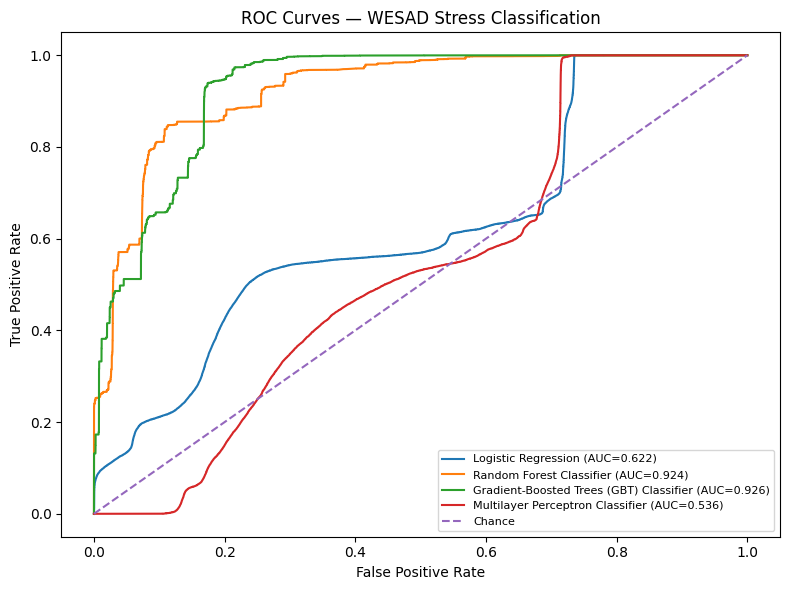

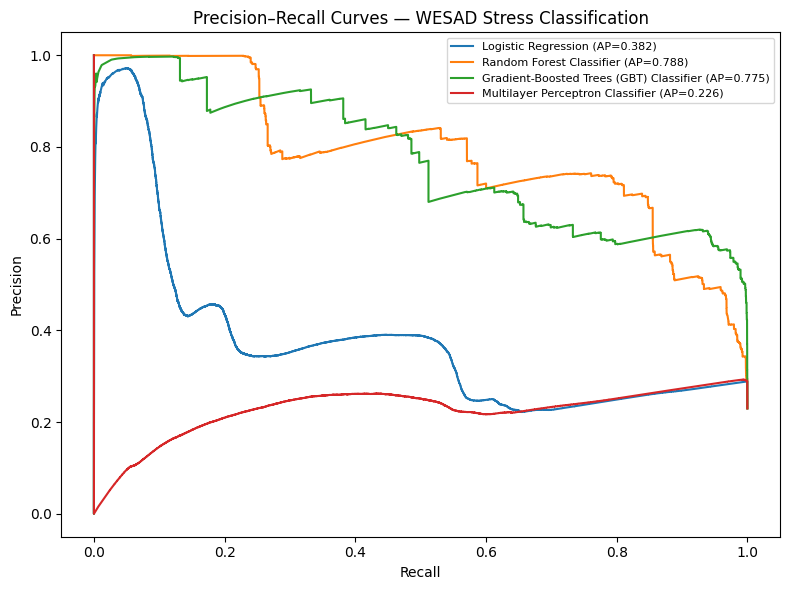

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

fig, ax = plt.subplots(figsize=(8, 6))
for name, (y_true, y_score) in curve_data.items():
    fpr, tpr, _ = roc_curve(y_true, y_score)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — WESAD Stress Classification")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, (y_true, y_score) in curve_data.items():
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    ax.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_true, y_score):.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curves — WESAD Stress Classification")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

### Show confusion matrices and test prediction stability under feature perturbations.\n

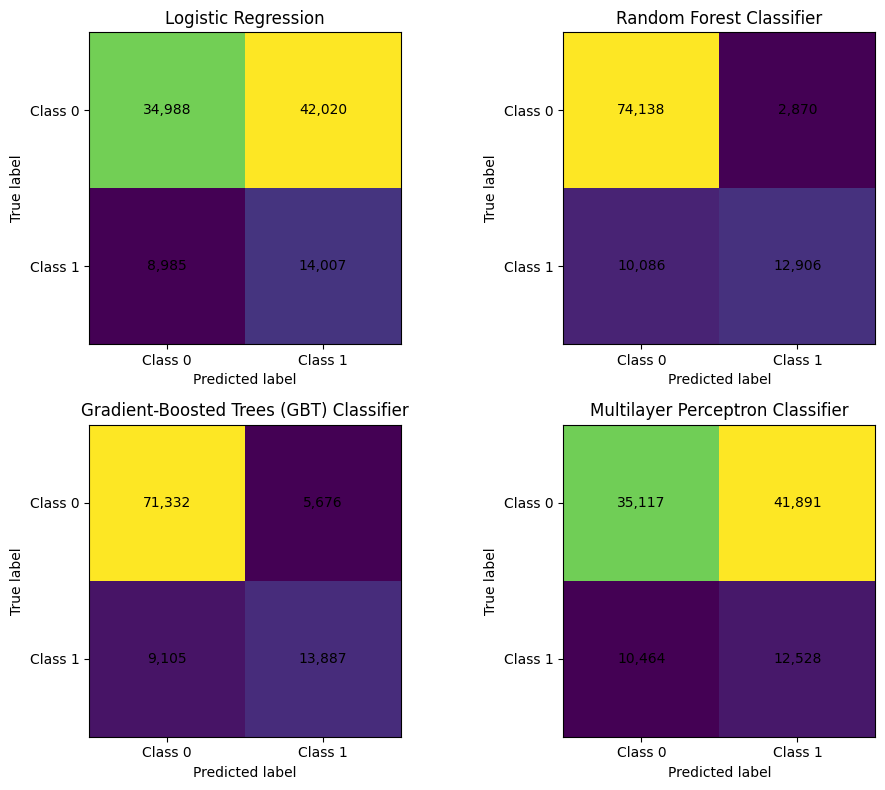

Logistic Regression | noise=0.01 | agreement=1.0000
Logistic Regression | noise=0.05 | agreement=1.0000
Logistic Regression | noise=0.10 | agreement=1.0000
Random Forest Classifier | noise=0.01 | agreement=0.9872
Random Forest Classifier | noise=0.05 | agreement=0.9618
Random Forest Classifier | noise=0.10 | agreement=0.9330
Gradient-Boosted Trees (GBT) Classifier | noise=0.01 | agreement=0.9868
Gradient-Boosted Trees (GBT) Classifier | noise=0.05 | agreement=0.9510
Gradient-Boosted Trees (GBT) Classifier | noise=0.10 | agreement=0.9114
Multilayer Perceptron Classifier | noise=0.01 | agreement=0.9988
Multilayer Perceptron Classifier | noise=0.05 | agreement=0.9940
Multilayer Perceptron Classifier | noise=0.10 | agreement=0.9838


,Model,Noise_SD,Prediction_Agreement,Prediction_Change_Percent
0,Logistic Regression,0.01,1.0000,0.00
1,Logistic Regression,0.05,1.0000,0.00
2,Logistic Regression,0.10,1.0000,0.00
3,Random Forest Classifier,0.01,0.9872,1.28
4,Random Forest Classifier,0.05,0.9618,3.82
5,Random Forest Classifier,0.10,0.9330,6.70
6,Gradient-Boosted Trees (GBT) Classifier,0.01,0.9868,1.32
7,Gradient-Boosted Trees (GBT) Classifier,0.05,0.9510,4.90
8,Gradient-Boosted Trees (GBT) Classifier,0.10,0.9114,8.86
9,Multilayer Perceptron Classifier,0.01,0.9988,0.12


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, cm) in zip(axes.ravel(), confusion_matrices.items()):
    ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], labels=["Class 0", "Class 1"])
    ax.set_yticks([0, 1], labels=["Class 0", "Class 1"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
plt.tight_layout()
plt.show()

# Perturb a bounded, reproducible subset of held-out feature vectors.
STABILITY_ROWS = min(5_000, test_n)
stability_rows = test.select("features", "label").limit(STABILITY_ROWS).collect()
X_stability = np.vstack([np.asarray(r["features"].toArray(), dtype=float) for r in stability_rows])
y_stability = np.array([int(r["label"]) for r in stability_rows])
rng = np.random.default_rng(SEED)

stability_rows_out = []
for name, model in fitted_models.items():
    base_df = spark.createDataFrame(
        [(Vectors.dense(x.tolist()), int(y)) for x, y in zip(X_stability, y_stability)],
        schema=["features", "label"]
    )
    base_pred = model.transform(base_df).select("prediction").collect()
    base_labels = np.array([int(r["prediction"]) for r in base_pred])

    for noise_sd in [0.01, 0.05, 0.10]:
        noise = np.random.default_rng(SEED + int(noise_sd * 1000)).normal(
            loc=0.0, scale=noise_sd, size=X_stability.shape
        )
        X_perturbed = X_stability + noise
        perturbed_df = spark.createDataFrame(
            [(Vectors.dense(x.tolist()), int(y)) for x, y in zip(X_perturbed, y_stability)],
            schema=["features", "label"]
        )
        perturbed_pred = model.transform(perturbed_df).select("prediction").collect()
        perturbed_labels = np.array([int(r["prediction"]) for r in perturbed_pred])
        agreement = float(np.mean(base_labels == perturbed_labels))
        stability_rows_out.append({
            "Model": name,
            "Noise_SD": noise_sd,
            "Prediction_Agreement": agreement,
            "Prediction_Change_Percent": (1.0 - agreement) * 100.0
        })
        print(f"{name} | noise={noise_sd:.2f} | agreement={agreement:.4f}")

stability_df = pd.DataFrame(stability_rows_out)
display(stability_df)


### Explain the best model using a surrogate and SHAP where available.\n

Best model by ROC-AUC: Gradient-Boosted Trees (GBT) Classifier
Surrogate fidelity against best Spark model: 0.799


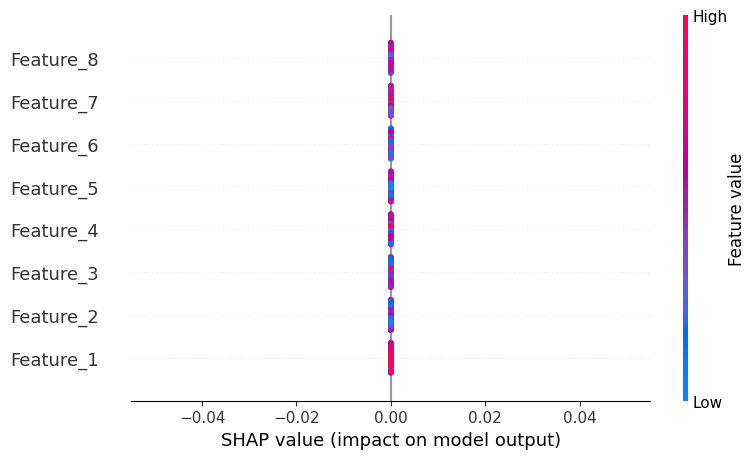

SHAP values explain the surrogate, not the Spark model directly.


In [ ]:
best_name = str(results_df.iloc[0]["Model"])
best_spark_model = fitted_models[best_name]
print("Best model by ROC-AUC:", best_name)

# Explain the selected Spark model through a clearly labelled local surrogate.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_train_local = np.vstack([
    np.asarray(r["features"].toArray(), dtype=float)
    for r in fit_train.select("features").limit(8000).collect()
])
train_local_rows = fit_train.select("features").limit(len(X_train_local)).collect()
y_surrogate = np.array([
    int(r["prediction"])
    for r in best_spark_model.transform(
        spark.createDataFrame([(Vectors.dense(x.tolist()),) for x in X_train_local], ["features"])
    ).select("prediction").collect()
])

X_test_local = np.vstack([
    np.asarray(r["features"].toArray(), dtype=float)
    for r in test.select("features").limit(1000).collect()
])
y_test_surrogate = np.array([
    int(r["prediction"])
    for r in best_spark_model.transform(
        spark.createDataFrame([(Vectors.dense(x.tolist()),) for x in X_test_local], ["features"])
    ).select("prediction").collect()
])

surrogate = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
surrogate.fit(X_train_local, y_surrogate)
fidelity = accuracy_score(y_test_surrogate, surrogate.predict(X_test_local))
print("Surrogate fidelity against best Spark model:", round(float(fidelity), 4))

feature_names = [f"Feature_{i+1}" for i in range(X_train_local.shape[1])]
try:
    import shap
    explainer = shap.TreeExplainer(surrogate)
    shap_values = explainer.shap_values(X_test_local[:200])
    if isinstance(shap_values, list):
        values_for_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
    else:
        values_for_plot = np.asarray(shap_values)
        if values_for_plot.ndim == 3:
            values_for_plot = values_for_plot[:, :, 1]
    shap.summary_plot(values_for_plot, X_test_local[:200], feature_names=feature_names, show=True)
    print("SHAP values explain the surrogate, not the Spark model directly.")
except Exception as exc:
    print("SHAP plot unavailable:", type(exc).__name__, str(exc)[:300])
    importances = surrogate.feature_importances_
    top = np.argsort(importances)[-15:][::-1]
    plt.figure(figsize=(8, 5))
    plt.barh([feature_names[i] for i in top][::-1], importances[top][::-1])
    plt.xlabel("Surrogate feature importance")
    plt.title("Top features in surrogate model")
    plt.tight_layout()
    plt.show()


### Save evaluation tables, perturbation results, plots, and model metadata to Google Drive.


In [ ]:
RESULTS_DIR = Path("/content/drive/MyDrive/wesad_task5_outputs")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_DIR / "task5_model_metrics.csv", index=False)
stability_df.to_csv(RESULTS_DIR / "task5_perturbation_stability.csv", index=False)

for name, cm in confusion_matrices.items():
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    pd.DataFrame(
        cm,
        index=["Actual_Non_stress", "Actual_Stress"],
        columns=["Predicted_Non_stress", "Predicted_Stress"]
    ).to_csv(RESULTS_DIR / f"confusion_matrix_{safe_name}.csv")

metadata = {
    "task2_source": str(TASK2_DIR),
    "training_rows_available": int(train_full.count()),
    "test_rows_available": int(test_full.count()),
    "training_sample_rows": int(train_n),
    "model_fitting_rows": int(fit_train.count()),
    "threshold_validation_rows": int(threshold_validation.count()),
    "decision_thresholds": chosen_thresholds,
    "test_sample_rows": int(test_n),
    "training_participants": train_subjects,
    "test_participants": test_subjects,
    "models": results_df["Model"].tolist(),
    "metrics": ["Accuracy", "ROC-AUC", "PR-AUC", "Weighted Precision", "Weighted Recall", "Weighted F1", "Confusion Matrix"],
    "stability_noise_standard_deviations": [0.01, 0.05, 0.10],
    "explainability": "SHAP TreeExplainer on a Random Forest surrogate of the best Spark model; interpret as surrogate explanations.",
    "best_model_by_roc_auc": best_name,
    "status": "completed"
}
(RESULTS_DIR / "task5_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved Task 5 results to:", RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(p.name, "(directory)" if p.is_dir() else f"{p.stat().st_size:,} bytes")

fit_train.unpersist()
threshold_validation.unpersist()
train_sample.unpersist()
test.unpersist()

Saved Task 5 results to: /content/drive/MyDrive/wesad_task5_outputs
confusion_matrix_gradient_boosted_trees_gbt_classifier.csv 93 bytes
confusion_matrix_logistic_regression.csv 94 bytes
confusion_matrix_multilayer_perceptron_classifier.csv 95 bytes
confusion_matrix_random_forest_classifier.csv 94 bytes
task5_metadata.json 1,345 bytes
task5_model_metrics.csv 963 bytes
task5_perturbation_stability.csv 723 bytes


DataFrame[features: vector, label: double, target_text: string, subject_id: string, sample_index: bigint]